Label-noise robustness BERT

In [1]:
import json
import shutil
import time
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import Dataset
from sklearn.metrics import classification_report, confusion_matrix
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
NOISE_RATE = 0.10
set_seed(SEED)

C:\Users\oofuc\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SPLITS_DIR = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")

train_df = pd.read_csv(SPLITS_DIR / "noise10" / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")  # original, unmodified — never touch val/test labels

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

LABEL_ORDER = list(label_encoder.classes_)
NUM_CLASSES = len(LABEL_ORDER)
id2label = {i: c for i, c in enumerate(LABEL_ORDER)}
label2id = {c: i for i, c in enumerate(LABEL_ORDER)}

train_df["label"] = label_encoder.transform(train_df["category"])  # noisy labels, by design
val_df["label"] = label_encoder.transform(val_df["category"])

print("Train (noisy) rows:", len(train_df), "| flipped:", int(train_df["is_flipped"].sum()))
print("Val (clean) rows:", len(val_df))
print("Classes:", LABEL_ORDER)

Train (noisy) rows: 50000 | flipped: 5000
Val (clean) rows: 48178
Classes: ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']


In [3]:
MODEL_CHECKPOINT = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

SAMPLE_N = 20000
sample_lengths = (
    train_df["text"]
    .sample(n=min(SAMPLE_N, len(train_df)), random_state=SEED)
    .apply(lambda t: len(tokenizer.encode(t, add_special_tokens=True)))
)
p95_len = int(np.percentile(sample_lengths, 95))
MAX_LENGTH = int(np.clip(p95_len, 1, 512))
MAX_LENGTH = min(((MAX_LENGTH + 7) // 8) * 8, 512)
print(f"95th percentile subword length: {p95_len}, MAX_LENGTH: {MAX_LENGTH}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1000 > 512). Running this sequence through the model will result in indexing errors


95th percentile subword length: 756, MAX_LENGTH: 512


In [4]:
train_ds = Dataset.from_pandas(train_df[["text", "label"]].reset_index(drop=True))
val_ds = Dataset.from_pandas(val_df[["text", "label"]].reset_index(drop=True))


def tokenize_fn(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH, padding=False)


train_ds = train_ds.map(tokenize_fn, batched=True, remove_columns=["text"])
val_ds = val_ds.map(tokenize_fn, batched=True, remove_columns=["text"])


Map:   0%|          | 0/50000 [00:00<?, ? examples/s]


Map:   2%|▏         | 1000/50000 [00:00<00:07, 6855.45 examples/s]


Map:   4%|▍         | 2000/50000 [00:00<00:07, 6392.82 examples/s]


Map:   6%|▌         | 3000/50000 [00:00<00:06, 7190.62 examples/s]


Map:   8%|▊         | 4000/50000 [00:00<00:06, 7051.53 examples/s]


Map:  10%|█         | 5000/50000 [00:00<00:05, 7778.22 examples/s]

... (77 outputs left out)


Map:  95%|█████████▌| 46000/48178 [00:05<00:00, 9387.14 examples/s]


Map:  98%|█████████▊| 47000/48178 [00:05<00:00, 8298.92 examples/s]


Map: 100%|█████████▉| 48000/48178 [00:05<00:00, 8633.28 examples/s]


Map: 100%|██████████| 48178/48178 [00:05<00:00, 8949.07 examples/s]

In [5]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3758.05it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [6]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    report = classification_report(
        labels, preds, target_names=LABEL_ORDER, output_dict=True, zero_division=0
    )
    return {
        "accuracy": report["accuracy"],
        "macro_f1": report["macro avg"]["f1-score"],
        "weighted_f1": report["weighted avg"]["f1-score"],
    }

In [7]:
MODELS_DIR = Path("../../weights/noise10/bert")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

training_args = TrainingArguments(
    output_dir=str(MODELS_DIR),
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=100,
    fp16=torch.cuda.is_available(),
    seed=SEED,
    data_seed=SEED,
    report_to="none",
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [8]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
)

start_time = time.time()
train_result = trainer.train()
train_time_sec = time.time() - start_time
print(f"Training took {train_time_sec:.1f}s")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.855489,0.486172,0.859978,0.841764,0.859868
2,0.724662,0.434310,0.873718,0.854517,0.873503
3,0.591666,0.443182,0.871539,0.851778,0.871311



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.83it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.82it/s]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.16it/s]

... (3 outputs left out)


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.01s/it]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

[transformers] There were unexpected keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.beta', 'bert.embeddings.LayerNorm.gamma', 'bert.encoder.layer.0.attention.output.LayerNorm.beta', 'bert.encoder.layer.0.attention.output.LayerNorm.gamma', 'bert.encoder.layer.0.output.LayerNorm.beta', 'bert.encoder.layer.0.output.LayerNorm.gamma', 'bert.encoder.layer.1.attention.output.LayerNorm.beta', 'bert.encoder.layer.1.attention.output.LayerNorm.gamma', 'bert.encoder.layer.1.output.LayerNorm.beta', 'bert.encoder.layer.1.output.LayerNorm.gamma', 'bert.encoder.layer.2.attention.output.LayerNorm.beta', 'bert.encoder.layer.2.attention.output.LayerNorm.gamma', 'bert.encoder.layer.2.output.LayerNorm.beta', 'bert.encoder.layer.2.output.LayerNorm.gamma', 'bert.encoder.layer.3.attention.output.LayerNorm.beta', 'bert.encoder.layer.3.attention.output.LayerNorm.gamma', 'bert.encoder.layer.3.output.LayerNorm.beta', 'bert.encoder.layer.3.output.LayerNorm.gamma', 'bert.encoder.layer.4.attention.

Training took 3381.2s


In [9]:
inf_start = time.time()
val_output = trainer.predict(val_ds)
inf_time_sec = time.time() - inf_start

y_pred = np.argmax(val_output.predictions, axis=-1)
y_val = np.array(val_ds["label"])

report_dict = classification_report(
    y_val, y_pred, target_names=LABEL_ORDER, output_dict=True, zero_division=0
)
print(classification_report(y_val, y_pred, target_names=LABEL_ORDER, zero_division=0))

cm = confusion_matrix(y_val, y_pred)
val_accuracy = report_dict["accuracy"]
print(f"Val accuracy: {val_accuracy:.4f}")
print(f"Inference time: {inf_time_sec:.2f}s total, {inf_time_sec / len(val_df) * 1000:.3f} ms/sample")
print("\nBERT_a in-distribution test accuracy for comparison: 0.9018 (see results/bert/BERT_a_metrics.json)")

               precision    recall  f1-score   support

     Business       0.83      0.82      0.83      6323
Entertainment       0.89      0.92      0.90     12064
       Health       0.81      0.83      0.82      4196
     Politics       0.88      0.84      0.86      6238
      Science       0.73      0.72      0.72      1609
       Sports       0.96      0.95      0.95      5854
   Technology       0.87      0.85      0.86      5828
        World       0.87      0.90      0.88      6066

     accuracy                           0.87     48178
    macro avg       0.86      0.85      0.85     48178
 weighted avg       0.87      0.87      0.87     48178

Val accuracy: 0.8737
Inference time: 255.14s total, 5.296 ms/sample

BERT_a in-distribution test accuracy for comparison: 0.9018 (see results/bert/BERT_a_metrics.json)


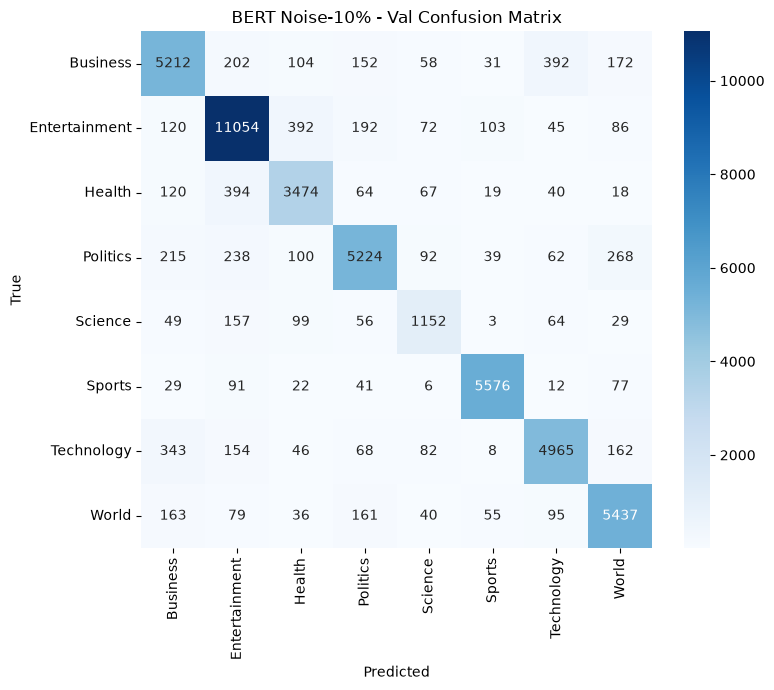

In [10]:
RESULTS_DIR = Path("../../../results/bert")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("BERT Noise-10% - Val Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "bert_noise10_confusion_matrix.png", dpi=150)
plt.show()
plt.close()

In [11]:
trainer.save_model(str(MODELS_DIR))
tokenizer.save_pretrained(str(MODELS_DIR))

metrics = {
    "model_family": "bert",
    "model_name": f"{MODEL_CHECKPOINT}-noise10",
    "run_timestamp": pd.Timestamp.now("UTC").isoformat(),
    "label_order": LABEL_ORDER,
    "noise_rate": NOISE_RATE,
    "config": {
        "max_length": MAX_LENGTH,
        "batch_size": training_args.per_device_train_batch_size,
        "epochs_planned": training_args.num_train_epochs,
        "epochs_trained": trainer.state.epoch,
        "learning_rate": training_args.learning_rate,
    },
    "train": {
        "n_train": len(train_df),
        "n_flipped": int(train_df["is_flipped"].sum()),
        "train_time_sec": train_time_sec,
        "epochs_trained": trainer.state.epoch,
        "history": {"log_history": trainer.state.log_history},
    },
    "test": {
        "n_test": len(val_df),
        "eval_split": "val (original, unmodified)",
        "accuracy": float(val_accuracy),
        "macro_precision": float(report_dict["macro avg"]["precision"]),
        "macro_recall": float(report_dict["macro avg"]["recall"]),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class": {
            cls: {
                "precision": float(report_dict[cls]["precision"]),
                "recall": float(report_dict[cls]["recall"]),
                "f1": float(report_dict[cls]["f1-score"]),
                "support": int(report_dict[cls]["support"]),
            }
            for cls in LABEL_ORDER
        },
        "confusion_matrix": cm.tolist(),
        "inference_time_sec_total": inf_time_sec,
        "inference_time_ms_per_sample": inf_time_sec / len(val_df) * 1000,
    },
    "environment": {
        "framework": "pytorch+transformers",
        "framework_version": torch.__version__,
        "device": "GPU" if torch.cuda.is_available() else "CPU",
        "seed": SEED,
    },
}

with open(RESULTS_DIR / "bert_noise10_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

for sub in MODELS_DIR.glob("checkpoint-*"):
    if sub.is_dir():
        shutil.rmtree(sub)

print("Saved:")
print(" ", MODELS_DIR)
print(" ", RESULTS_DIR / "bert_noise10_metrics.json")
print(" ", RESULTS_DIR / "bert_noise10_confusion_matrix.png")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.39it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.38it/s]

Saved:
  ..\..\weights\noise10\bert
  ..\..\..\results\bert\bert_noise10_metrics.json
  ..\..\..\results\bert\bert_noise10_confusion_matrix.png
